In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (50000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


In [4]:
x_train = tf.image.resize(x_train[:5000], (96, 96))
x_test = tf.image.resize(x_test[:1000], (96, 96))

y_train = y_train[:5000]
y_test = y_test[:1000]

x_train = tf.keras.applications.mobilenet_v2.preprocess_input(x_train)
x_test = tf.keras.applications.mobilenet_v2.preprocess_input(x_test)

In [5]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 5s 1us/step


In [6]:

base_model.trainable = False

In [7]:
x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(128, activation='relu')(x)

x = Dropout(0.3)(x)

output = Dense(10, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [9]:
history = model.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 111ms/step - accuracy: 0.5142 - loss: 1.5563 - val_accuracy: 0.7980 - val_loss: 0.6256
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 14s 112ms/step - accuracy: 0.8307 - loss: 0.5202 - val_accuracy: 0.8140 - val_loss: 0.5824
Epoch 3/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 13s 105ms/step - accuracy: 0.8725 - loss: 0.3768 - val_accuracy: 0.8160 - val_loss: 0.5681


In [10]:
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(
    x_train,
    y_train,
    epochs=2,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/2
125/125 ━━━━━━━━━━━━━━━━━━━━ 21s 127ms/step - accuracy: 0.7458 - loss: 0.7446 - val_accuracy: 0.8250 - val_loss: 0.5748
Epoch 2/2
125/125 ━━━━━━━━━━━━━━━━━━━━ 14s 116ms/step - accuracy: 0.8162 - loss: 0.5420 - val_accuracy: 0.8230 - val_loss: 0.5857


In [11]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", accuracy * 100, "%")

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step - accuracy: 0.8531 - loss: 0.4774
Test Accuracy: 83.89999866485596 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 785ms/step


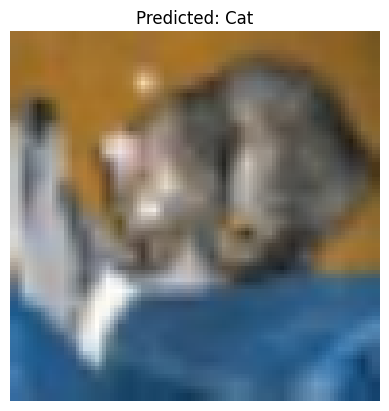

In [12]:
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

prediction = model.predict(x_test[:1])

predicted_class = np.argmax(prediction[0])

plt.imshow(
    (x_test[0].numpy() + 1) / 2
)

plt.title("Predicted: " + class_names[predicted_class])
plt.axis('off')
plt.show()